# Determining the effect of the WR selection criteria on results

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
from scipy.stats import gaussian_kde
from posydon.utils.common_functions import convert_metallicity_to_string
from posydon.popsyn.distributions import PowerLawPeriod

from wr_population.paths import FIGURE_DIR, EXTRA_FIGURE_DIR
from wr_population.io import load_metallicity
from wr_population.classification import (classify_WR, make_binary_mask,
                                          formation_channel_masks, CHANNEL_COLOURS)
from wr_population.plotting import METALLICITY_COLOURS, plot_period_histogram

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))
COLORS = METALLICITY_COLOURS
from functools import partial

from wr_population.plotting import use_posydon_style
use_posydon_style()


In [2]:
metallicities = [1.0]  # in units of Zsun

WR_data = {Z: load_metallicity(Z) for Z in metallicities}

In [3]:
# selection criteria to compare
classify_WR_normal = classify_WR                                      # tau > 1.5
classify_WR_MS = partial(classify_WR, exclude_H_burning=False)        # also core-H burning WNL
classify_WR_optical_depth = partial(classify_WR, tau_min=0.5)         # tau > 0.5

In [4]:
colours = CHANNEL_COLOURS

740.7161690267058
221.8155424276929 350.6600184190765 168.24060817993617


WNL: 1.0


Stable (S1): 36.185%


Stable (S2): 11.318%


Unstable (S1): 1.433%


...

Unstable (S1): 2.122%


Unstable (S2): 3.758%


No MT (S1): 14.745%


No MT (S2): 7.047%


Reverse Stable (S1): 2.478%


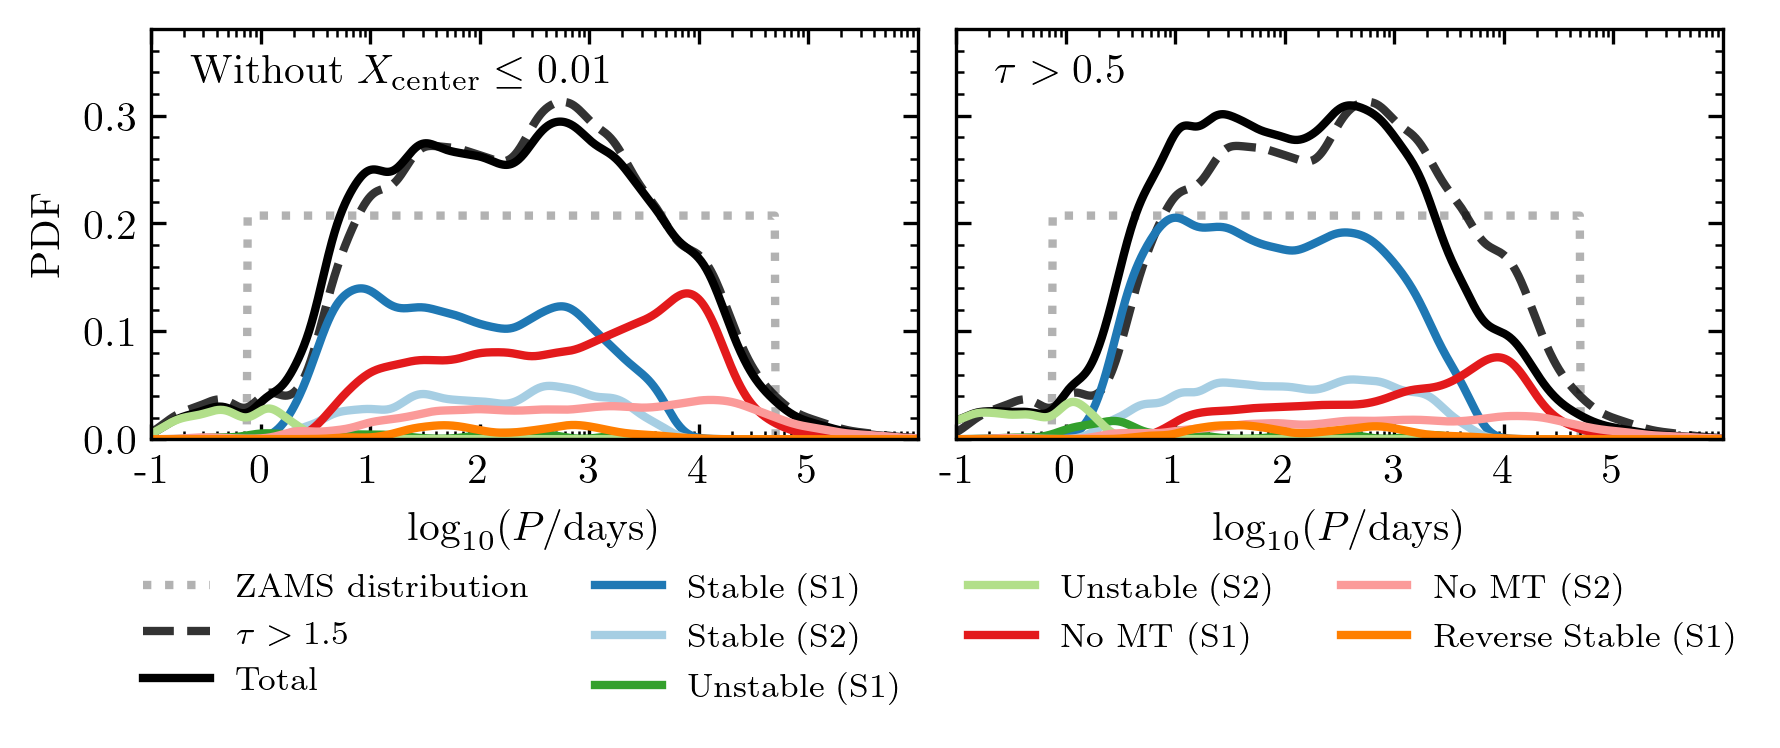

In [5]:

fig, axes  = plt.subplots(1, 2, figsize=(3.38*2, 2.535*0.7))

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=50000.0, slope=0.0)
x_eval = np.linspace(-1, 7, 1000)


mask = make_binary_mask(WR_data[1.0])


flatP = PDF_logP.pdf(10**x_eval)

for ax in axes:
    ax.plot(10**x_eval, flatP, ls=':',  color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

weights = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
period_array = WR_data[1.0]['period']

# plot original total distribution for comparison
WNL, WNE, WC = classify_WR_normal(WR_data[1.0])
WR_mask = WNL | WNE | WC

kde = gaussian_kde(np.log10(period_array[mask & WR_mask]), weights=weights[mask & WR_mask], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label=r'$\tau>1.5$', linewidth=2, alpha=0.8, ls='--')
axes[1].plot(10**x_eval, kde_eval, color='black', label=r'$\tau>1.5$', linewidth=2, alpha=0.8, ls='--')


count = 0
for label, mask_func in zip(['MS', 'Optical Depth'], [classify_WR_MS, classify_WR_optical_depth]):
    WNL, WNE, WC = mask_func(WR_data[1.0])
    WR_mask = WNL | WNE | WC
    print(weights[mask & WR_mask].sum())
    print(weights[mask & WNL].sum(), weights[mask & WNE].sum(), weights[mask & WC].sum())
    
    # plot total
    kde = gaussian_kde(np.log10(period_array[mask & WR_mask]), weights=weights[mask & WR_mask], bw_method=0.1)
    kde_eval = kde(x_eval)
    axes[count].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)
    
    metallicity = 1.0
    met_str = convert_metallicity_to_string(metallicity)

    channel_masks = formation_channel_masks(WR_data[metallicity], metallicity)
    MT_interactions = channel_masks
    
    # get covariance
    cho_cov = kde.cho_cov

    # different MT interactions
    print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
    total = 0
    not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
    for label, mt_mask in MT_interactions.items():
        if np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) == 0:
            continue  # Skip if no data points for this interaction type
        
        # plot histogram 
        kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
        kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
        kde_eval = kde(x_eval)
        fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
        total += fraction
        print(f"{label}: {fraction*100:.3f}%")
        axes[count].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])
    count += 1

    
    
for ax in axes:
    # Housekeeping for layout
    ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
    ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
    ax.set_ylim(0, 0.38)


axes[0].set_ylabel('PDF')
#axes[1].set_ylabel('PDF')
axes[1].set_yticklabels([])

axes[1].set_xlabel('$\log_{10}(P/\mathrm{days})$')
axes[0].text(0.05, 0.87, r'Without $X_\mathrm{center} \leq 0.01$ ', transform=axes[0].transAxes)
axes[1].text(0.05, 0.87, r'$\tau>0.5$', transform=axes[1].transAxes)

axes[0].legend(loc='upper left', bbox_to_anchor=(-0.05, -0.25), ncol=4)

plt.subplots_adjust(wspace=0.05, hspace=0.1)


figure_paths = str(FIGURE_DIR) + '/'
plt.savefig(figure_paths + 'pdf/MW_other_selection_criteria.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_other_selection_criteria.png', bbox_inches='tight', dpi=300)
plt.show()